<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C22_Notebook-26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

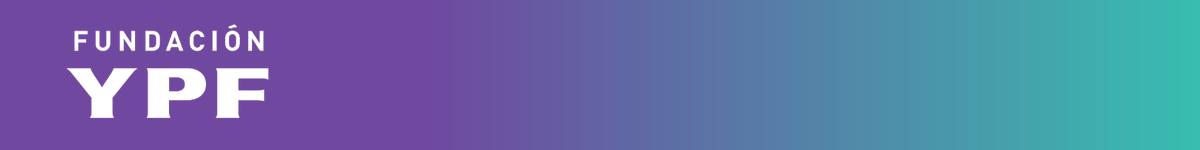

# Fundación YPF - Data Science

## Notebook 26: Métricas de evaluación de clustering

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: K-Means y DBSCAN sobre los mismos datos
* **Parte 2:** Método del codo (Elbow)
* **Parte 3:** Coeficiente de Silhouette
* **Parte 4:** Comparamos K-Means y DBSCAN con una métrica objetiva
* **Parte 5:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En las clases anteriores agrupamos a los clientes de un centro comercial con **K-Means** (Notebook 23) y con **DBSCAN** (Notebook 25), y decidimos si el resultado era bueno mirando los gráficos. Hoy vemos dos métricas para medirlo sin depender solo de la vista: el **método del codo** y el **coeficiente de Silhouette**.

**Datasets:**

* `clientes_mall.csv`: los mismos 200 clientes del centro comercial (el de las Notebooks 23 y 25). Lo usamos en la parte guiada.
* `blackfriday.csv`: compras de un Black Friday (el mismo de la Notebook 24). Lo usamos en el ejercicio de las salas.

Los dos archivos se descargan automáticamente desde la carpeta `dataset/` del repositorio, así que la notebook funciona en Colab, en VS Code o en Jupyter sin subir nada a mano.

In [29]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

URL_CLIENTES_MALL = "https://raw.githubusercontent.com/EmiiFernandez/actividades_data_sciente_ypf/main/dataset/clientes_mall.csv"
URL_BLACKFRIDAY = "https://raw.githubusercontent.com/EmiiFernandez/actividades_data_sciente_ypf/main/dataset/blackfriday.csv.gz"

## Parte 1: Repaso: K-Means y DBSCAN sobre los mismos datos

Volvemos a los clientes del centro comercial. Reproducimos el K-Means con k = 5 de la Notebook 23 y el DBSCAN con eps = 0.5 y min_samples = 5 de la Notebook 25, agrupando por **ingreso anual** y **puntaje de gasto**.

In [30]:
clientes = pd.read_csv(URL_CLIENTES_MALL).drop(columns=["Unnamed: 0", "CustomerID"])
clientes.columns = ["Genero", "Edad", "Ingreso", "Puntaje"]

# Igual que en las Notebooks 23 y 25: nos quedamos con los clientes con datos numéricos completos
datos = clientes.dropna(subset=["Edad", "Ingreso", "Puntaje"]).reset_index(drop=True)
print("Clientes:", len(datos))

X = StandardScaler().fit_transform(datos[["Ingreso", "Puntaje"]])

Clientes: 161


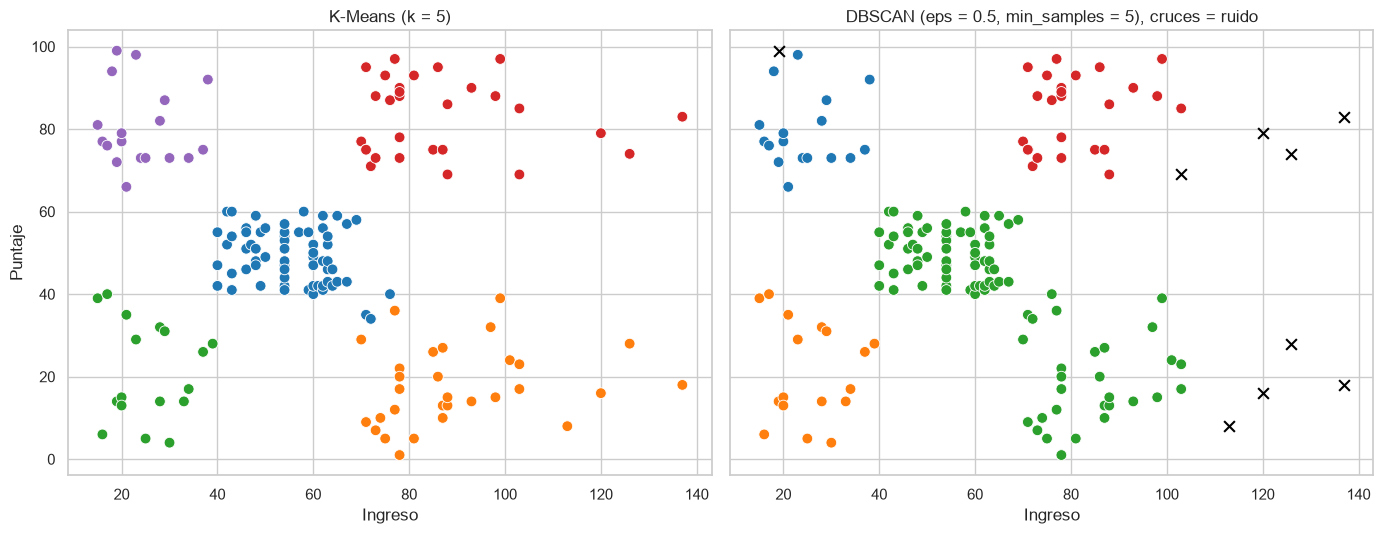

In [31]:
datos["cluster_kmeans"] = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
datos["cluster_dbscan"] = DBSCAN(eps=0.5, min_samples=5).fit_predict(X)

ruido = datos["cluster_dbscan"] == -1

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
sns.scatterplot(data=datos, x="Ingreso", y="Puntaje", hue="cluster_kmeans", palette="tab10", s=60, ax=ax[0], legend=False)
ax[0].set_title("K-Means (k = 5)")
sns.scatterplot(data=datos[~ruido], x="Ingreso", y="Puntaje", hue="cluster_dbscan", palette="tab10", s=60, ax=ax[1], legend=False)
ax[1].scatter(datos.loc[ruido, "Ingreso"], datos.loc[ruido, "Puntaje"], marker="x", color="black", s=60)
ax[1].set_title("DBSCAN (eps = 0.5, min_samples = 5), cruces = ruido")
plt.tight_layout()
plt.show()

Los dos métodos separan grupos parecidos, pero decidimos K-Means con k = 5 y DBSCAN con esos parámetros **mirando el gráfico**. Si tuviéramos que elegir entre varias combinaciones, o explicarle a alguien por qué el resultado es bueno, necesitamos un número. Eso es lo que buscamos ahora.

## Parte 2: Método del codo (Elbow)

K-Means necesita que le indiquemos **k** de antemano. La **inercia** (`inertia_` en scikit-learn) es la suma de las distancias al cuadrado de cada punto a su centroide: mide qué tan compactos quedan los clusters. Siempre baja al aumentar k (con k = n clusters la inercia es 0), así que no buscamos el mínimo sino el punto donde **deja de bajar mucho**: el codo de la curva.

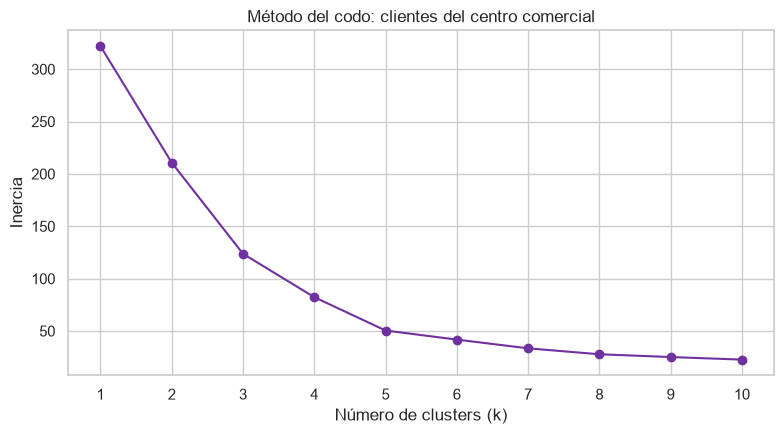

In [9]:
valores_k = range(1, 11)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_ for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, inercias, "o-", color="#7030A0")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo: clientes del centro comercial")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

La inercia cae fuerte hasta k = 5 y después la mejora se achica: ese es el codo. Coincide con el k = 5 que ya veníamos usando desde la Notebook 23, pero ahora lo justificamos con la curva y no solo con la vista.

## Parte 3: Coeficiente de Silhouette

El método del codo compara cada clustering con **sí mismo** (su propia inercia). El coeficiente de Silhouette compara, para cada punto, qué tan parecido es a su propio cluster frente a qué tan parecido es al cluster más cercano:

* **a(i):** distancia media del punto i con el resto de su cluster (cohesión).
* **b(i):** distancia media del punto i con los puntos del cluster más cercano (separación).
* **s(i) = (b(i) − a(i)) / max(a(i), b(i))**, entre −1 y 1. Cerca de 1 es un punto bien ubicado en su cluster, cerca de 0 está en el límite entre dos clusters, y negativo probablemente quedó en el cluster equivocado.

El coeficiente de Silhouette del clustering es el promedio de s(i) de todos los puntos. A diferencia de la inercia, **sí sirve para comparar entre valores de k** porque no depende de la escala de la inercia.

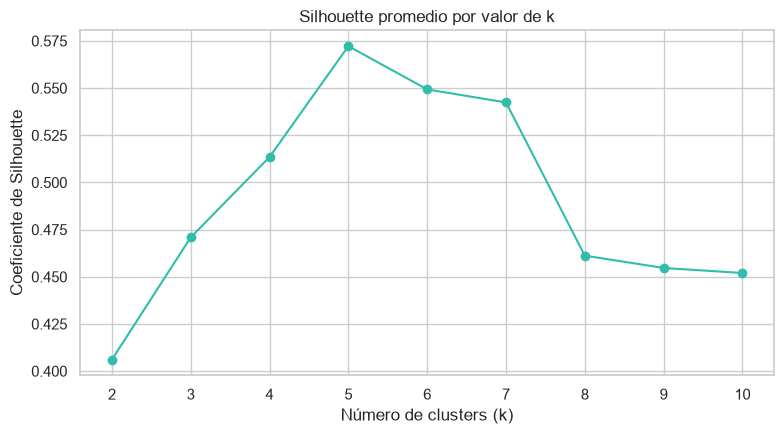

k con mayor Silhouette: 5 | valor: 0.572


In [10]:
valores_k = range(2, 11)
siluetas = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)) for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(list(valores_k), siluetas, "o-", color="#30BEAA")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de Silhouette")
plt.title("Silhouette promedio por valor de k")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

mejor_k = list(valores_k)[int(np.argmax(siluetas))]
print("k con mayor Silhouette:", mejor_k, "| valor:", round(max(siluetas), 3))

### 3.1 Perfil de Silhouette por punto

El promedio esconde si hay puntos mal ubicados dentro de un cluster que en general anda bien. Graficamos s(i) de cada punto, agrupado por cluster, para el k con mayor Silhouette.

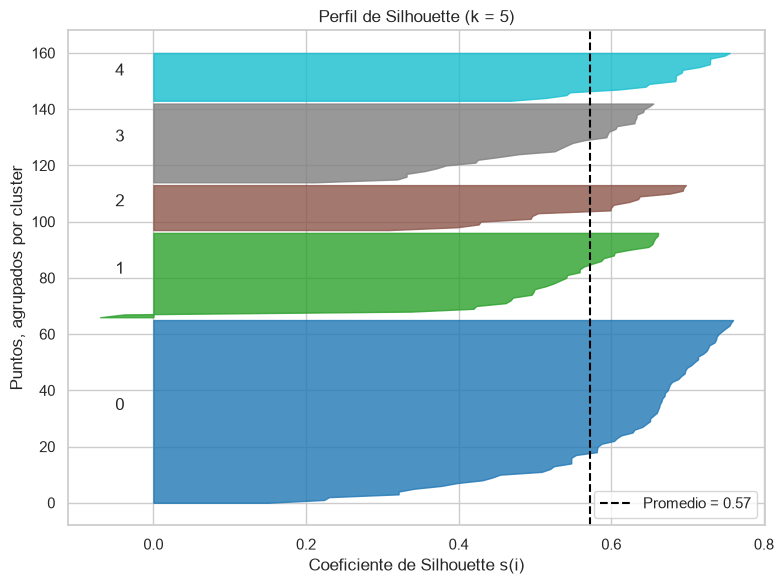

In [11]:
kmeans_final = KMeans(n_clusters=mejor_k, n_init=10, random_state=RANDOM_STATE).fit(X)
etiquetas = kmeans_final.labels_
valores_s = silhouette_samples(X, etiquetas)

fig, ax = plt.subplots(figsize=(8, 6))
inicio = 0
colores = plt.cm.tab10(np.linspace(0, 1, mejor_k))
for cluster in range(mejor_k):
    s_cluster = np.sort(valores_s[etiquetas == cluster])
    fin = inicio + len(s_cluster)
    ax.fill_betweenx(np.arange(inicio, fin), 0, s_cluster, color=colores[cluster], alpha=0.8)
    ax.text(-0.05, (inicio + fin) / 2, str(cluster))
    inicio = fin

ax.axvline(valores_s.mean(), color="black", linestyle="--", label=f"Promedio = {valores_s.mean():.2f}")
ax.set_xlabel("Coeficiente de Silhouette s(i)")
ax.set_ylabel("Puntos, agrupados por cluster")
ax.set_title(f"Perfil de Silhouette (k = {mejor_k})")
ax.legend()
plt.tight_layout()
plt.show()

Se espera que, si los clusters están bien armados, el perfil de todos los grupos sea parejo y la mayoría de las barras llegue cerca del promedio o lo supere, sin valores negativos marcados. Un cluster con muchas barras cortas o negativas es candidato a revisarse: puede estar mezclado con otro o ser demasiado chico.

## Parte 4: Comparamos K-Means y DBSCAN con una métrica objetiva

En la Notebook 25 dejamos pendiente **validar con métricas** la comparación entre K-Means y DBSCAN. El coeficiente de Silhouette funciona para cualquier método de clustering, así que lo calculamos para los dos. DBSCAN marca ruido con la etiqueta −1: lo dejamos afuera porque no es un cluster, es la ausencia de uno.

In [12]:
silhouette_kmeans = silhouette_score(X, datos["cluster_kmeans"])

sin_ruido = datos["cluster_dbscan"] != -1
silhouette_dbscan = silhouette_score(X[sin_ruido], datos.loc[sin_ruido, "cluster_dbscan"])

comparacion = pd.DataFrame({
    "método": ["K-Means (k = 5)", "DBSCAN (eps = 0.5, min_samples = 5)"],
    "silhouette": [round(silhouette_kmeans, 3), round(silhouette_dbscan, 3)],
})
comparacion

,método,silhouette
0,K-Means (k = 5),0.572
1,"DBSCAN (eps = 0.5, min_samples = 5)",0.472


K-Means queda con un Silhouette más alto que DBSCAN: arma clusters compactos de forma esférica, y en este dataset los grupos ya tienen esa forma, así que DBSCAN no gana nada por buscar densidad en lugar de eso. La ventaja de DBSCAN acá no es un Silhouette más alto, sino que **separa el ruido** en una categoría propia en vez de forzarlo dentro de un cluster. La métrica no dice solo "cuál es mejor": hay que leerla junto con lo que cada algoritmo hace con los datos.

## Parte 5: Ejercicio para las salas de Zoom

**Dataset:** `blackfriday.csv` (el mismo de la Notebook 24). Volvemos a la tabla de compradores que armamos ahí: una fila por usuario, con `compras`, `gasto_total`, `ticket`, `categorias`, `edad` y `log_compras`.

**Contexto:** en la Notebook 24 comparamos los perfiles de k = 3 y k = 4 y elegimos **k = 4 a ojo**, dejando dicho que íbamos a validar esa decisión con métricas más adelante.

**Objetivo:** usar el método del codo y el coeficiente de Silhouette para confirmar o corregir esa elección.

**Tiempo:** 50 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Método del codo.** Probá k de 2 a 10 sobre `X` (ya escalado) y graficá la inercia. ¿El codo coincide con k = 4?
2. **Silhouette.** Calculá el coeficiente de Silhouette para los mismos valores de k y graficalo. ¿Qué k da el mayor valor? ¿Coincide con el del codo?
3. **Elección final.** Elegí un k (no necesariamente el de mayor Silhouette: si dos valores quedan parecidos, pesá también la interpretabilidad, como en la Notebook 24) y entrená el K-Means final.
4. **Perfil de los clusters.** Calculá el perfil (medias de `compras`, `ticket`, `categorias`, `gasto_total`, `edad`) para el k elegido.
5. **Comparación.** ¿El k que elegiste con métricas es el mismo k = 4 de la Notebook 24? Si cambia, explicá qué le aporta el nuevo valor frente al anterior.

In [34]:
# Cargamos el dataset del ejercicio y reconstruimos la tabla de usuarios (igual que en la Notebook 24)
bf = pd.read_csv(URL_BLACKFRIDAY)

usuarios = bf.groupby("User_ID").agg(
    compras=("Purchase", "count"),
    gasto_total=("Purchase", "sum"),
    ticket=("Purchase", "mean"),
    categorias=("Product_Category_1", "nunique"),
    edad=("Age", "median"),
)
usuarios["log_compras"] = np.log1p(usuarios["compras"])

variables = ["log_compras", "ticket", "categorias"]
X_bf = StandardScaler().fit_transform(usuarios[variables])

print("Usuarios:", len(usuarios))
usuarios.describe().round(1)

Usuarios: 5891


,compras,gasto_total,ticket,categorias,edad,log_compras
count,5891.0,5891.0,5891.0,5891.0,5891.0,5891.0
mean,89.4,834765.6,9748.6,8.9,35.4,4.0
std,103.8,914642.8,1940.3,3.6,12.6,1.0
min,5.0,44108.0,2397.9,1.0,14.0,1.8
25%,24.0,231098.5,8442.4,6.0,29.0,3.2
50%,51.0,504608.0,9555.2,8.0,30.5,4.0
75%,111.0,1081927.0,10860.4,12.0,41.0,4.7
max,1002.0,10408280.0,18885.2,18.0,72.5,6.9


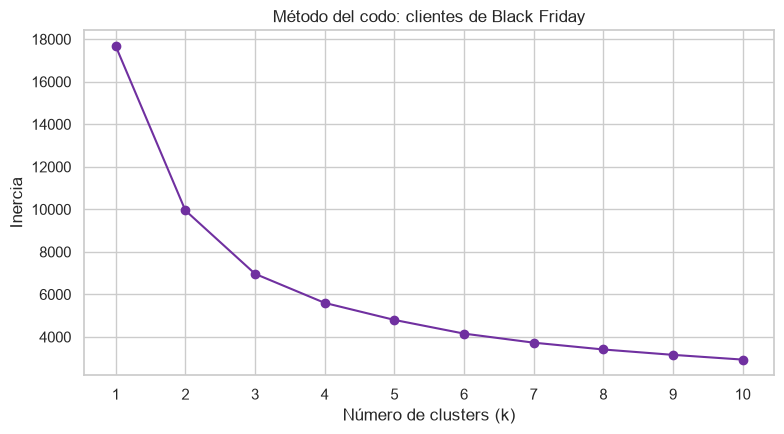

In [35]:
# 1. Método del codo
valores_k = range(1, 11)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_bf).inertia_ for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, inercias, "o-", color="#7030A0")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo: clientes de Black Friday")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

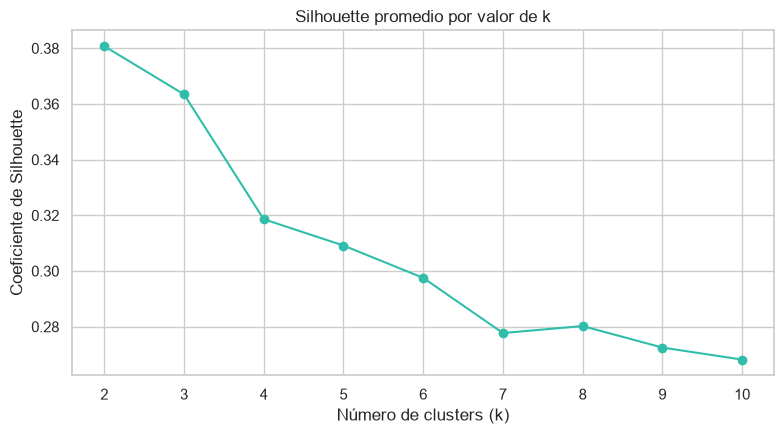

k con mayor Silhouette: 2 | valor: 0.381


In [36]:
# 2. Coeficiente de Silhouette
valores_k = range(2, 11)
siluetas = [silhouette_score(X_bf, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_bf)) for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(list(valores_k), siluetas, "o-", color="#30BEAA")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de Silhouette")
plt.title("Silhouette promedio por valor de k")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

mejor_k = list(valores_k)[int(np.argmax(siluetas))]
print("k con mayor Silhouette:", mejor_k, "| valor:", round(max(siluetas), 3))

In [41]:
columnas = ["compras", "ticket", "categorias"]

# Promedio general de todos los usuarios, para comparar cada cluster contra él
promedio = usuarios[columnas].mean().round(1).to_frame("Promedio general").T
promedio["usuarios"] = len(usuarios)

for k in [3, 4]:
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_bf)
    perfil = usuarios.assign(cluster=etiquetas).groupby("cluster")[columnas].mean().round(1)
    perfil["usuarios"] = pd.Series(etiquetas).value_counts().sort_index()

    # Silhouette promedio de cada cluster (y el general en la última fila)
    s_por_usuario = silhouette_samples(X_bf, etiquetas)
    perfil["silhouette"] = pd.Series(s_por_usuario).groupby(etiquetas).mean().round(3)
    promedio["silhouette"] = round(s_por_usuario.mean(), 3)

    print(f"k = {k}")
    display(pd.concat([perfil, promedio]))


k = 3


,compras,ticket,categorias,usuarios,silhouette
0,34.1,8507.8,6.5,2170,0.362
1,39.1,12102.9,6.9,1541,0.279
2,180.1,9319.5,12.6,2180,0.424
Promedio general,89.4,9748.6,8.9,5891,0.363


k = 4


,compras,ticket,categorias,usuarios,silhouette
0,28.1,8389.0,6.0,1763,0.352
1,78.8,9993.1,10.0,1784,0.268
2,240.5,8947.3,13.9,1259,0.363
3,31.2,12485.6,6.0,1085,0.294
Promedio general,89.4,9748.6,8.9,5891,0.319


K = 3 ==> 3 perfiles
    - Cluster 0 - Compra poco y barato
    - Cluster 1 - Compra poco, pero caro
    - Cluster 3 - Compradores frecuentes
K = 4 ==> El grupo de compradores frecuentes se parte en dos: un grupo intermedio (79 compras) y uno muy frecuente (240 compras). Ese grupo intermedio es el que tiene el Silhouette más bajo de todos (0,268). Es decir, k = 4 corta en dos un grupo que en los datos es continuo, no un grupo natural.

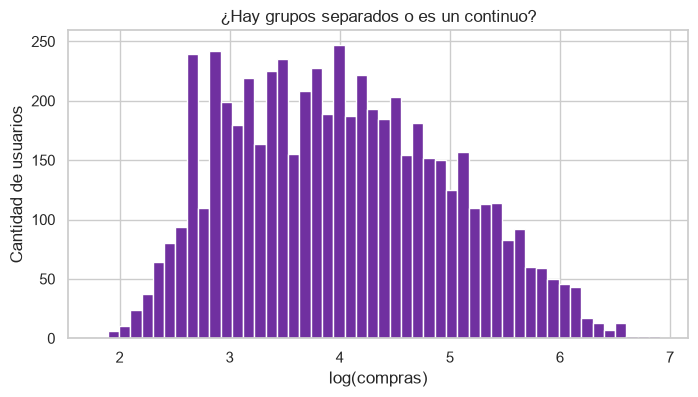

In [43]:
plt.figure(figsize=(8, 4))
plt.hist(usuarios["log_compras"], bins=50, color="#7030A0")
plt.xlabel("log(compras)")
plt.ylabel("Cantidad de usuarios")
plt.title("¿Hay grupos separados o es un continuo?")
plt.show()


**C¿grupos separados o continuo?**

Mirar la **forma general** (el "contorno" de las barras), no cada barra por separado.

* **Grupos separados:** se ven **varias montañas** con un **valle** entre ellas, es decir, una zona donde las barras bajan mucho (o casi a cero) y después vuelven a subir. Cada montaña es un grupo natural.
* **Continuo:** se ve **una sola montaña** (o una meseta) sin valles: las barras suben, se mantienen y después bajan de a poco. No hay ningún lugar donde los datos "se corten" solos.

**En este dataset:** las barras suben rápido, forman una meseta ancha y después bajan de a poco hacia la derecha (los pocos usuarios que compran muchísimo). Es una sola montaña, sin valles, o sea **un continuo**. Por eso el Silhouette ronda 0,3 para todos los k: K-Means corta la rampa en tramos, pero los usuarios cerca de cada corte están casi igual de cerca de los dos grupos. Los cortes los elegimos nosotros según lo que sirva para interpretar, no los marcan los datos.

Silhouette con k = 3 : 0.363
cluster
0    2170
1    1541
2    2180
Name: count, dtype: int64


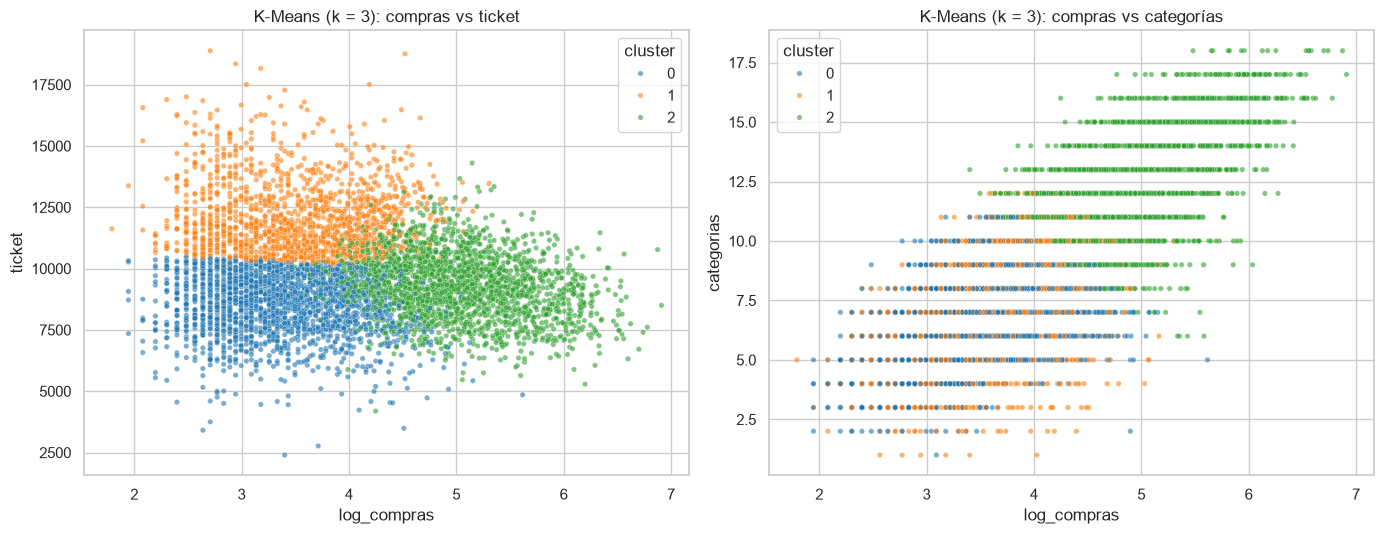

In [ ]:
# 3. K-Means final con el k elegido
k_elegido = 3  
km_final = KMeans(n_clusters=k_elegido, n_init=10, random_state=RANDOM_STATE).fit(X_bf)
usuarios["cluster"] = km_final.labels_

print("Silhouette con k =", k_elegido, ":", round(silhouette_score(X_bf, usuarios["cluster"]), 3))
print(usuarios["cluster"].value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=usuarios, x="log_compras", y="ticket", hue="cluster", palette="tab10", s=15, alpha=0.6, ax=ax[0])
ax[0].set_title(f"K-Means (k = {k_elegido}): compras vs ticket")
sns.scatterplot(data=usuarios, x="log_compras", y="categorias", hue="cluster", palette="tab10", s=15, alpha=0.6, ax=ax[1])
ax[1].set_title(f"K-Means (k = {k_elegido}): compras vs categorías")
plt.tight_layout()
plt.show()

In [48]:
# 4. Perfil de los clusters
columnas_perfil = ["compras", "ticket", "categorias", "gasto_total", "edad"]

perfil_final = usuarios.groupby("cluster")[columnas_perfil].mean().round(1)
perfil_final["usuarios"] = usuarios["cluster"].value_counts().sort_index()

promedio_general = usuarios[columnas_perfil].mean().round(1).to_frame("Promedio general").T
promedio_general["usuarios"] = len(usuarios)

pd.concat([perfil_final, promedio_general])


,compras,ticket,categorias,gasto_total,edad,usuarios
0,34.1,8507.8,6.5,285429.4,36.1,2170
1,39.1,12102.9,6.9,472773.6,35.5,1541
2,180.1,9319.5,12.6,1637467.0,34.6,2180
Promedio general,89.4,9748.6,8.9,834765.6,35.4,5891


In [50]:
# 5. Comparación con el k = 4 de la Notebook 24
km_k4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_bf)
usuarios["cluster_k4"] = km_k4.labels_

# a) Métricas lado a lado
comparacion_k = pd.DataFrame({
    "k": [k_elegido, 4],
    "inercia": [round(km_final.inertia_, 1), round(km_k4.inertia_, 1)],
    "silhouette": [round(silhouette_score(X_bf, usuarios["cluster"]), 3),
                   round(silhouette_score(X_bf, usuarios["cluster_k4"]), 3)],
})
display(comparacion_k)

# b) Perfil de k = 4 (el de k = 3 ya lo tenés en la celda 4)
perfil_k4 = usuarios.groupby("cluster_k4")[columnas_perfil].mean().round(1)
perfil_k4["usuarios"] = usuarios["cluster_k4"].value_counts().sort_index()
display(perfil_k4)

# c) ¿A dónde va cada usuario de k = 3 cuando pasamos a k = 4?
pd.crosstab(usuarios["cluster"], usuarios["cluster_k4"],
            rownames=["k = 3"], colnames=["k = 4"], margins=True)


,k,inercia,silhouette
0,3,6966.8,0.363
1,4,5600.5,0.319


,compras,ticket,categorias,gasto_total,edad,usuarios
cluster_k4,,,,,,
0,28.1,8389.0,6.0,227720.7,36.2,1763
1,78.8,9993.1,10.0,788350.6,35.1,1784
2,240.5,8947.3,13.9,2129584.9,34.5,1259
3,31.2,12485.6,6.0,394993.1,35.6,1085


k = 4,0,1,2,3,All
k = 3,,,,,
0,1743,427,0,0,2170
1,20,436,0,1085,1541
2,0,921,1259,0,2180
All,1763,1784,1259,1085,5891
